In [9]:
# testing YOLO algorithm for apple detection systems.
%pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [10]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [11]:
# Load a pre-trained YOLO model (e.g., nano version for speed)
model = YOLO("yolo11n.pt")  

In [12]:
import yaml
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import pathlib
%matplotlib inline
from collections import Counter
from IPython.display import display

In [13]:
# Load the YAML file
with open('../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/data.yaml', 'r') as f:
    data_yaml = yaml.safe_load(f)

data_yaml['train'] = '/kaggle/input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train'
data_yaml['val'] = '/kaggle/input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid'

# write to disk
with open('data.yaml', 'w') as f:
    yaml.dump(data_yaml, f)

In [14]:
!cat ../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['apple']

roboflow:
  workspace: lakshantha-dissanayake
  project: apple-detection-5z37o
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/lakshantha-dissanayake/apple-detection-5z37o/dataset/1

In [23]:

train_data_dir = Path("../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train")
valid_data_dir = Path("../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid")

'\nimages_dir = data_dir / "train" / "images"\nlabels_dir = data_dir / "train" / "labels"\n\nclass_names = data_yaml[\'names\']\n\n# Read the image file paths and annotations\nimage_paths = list(images_dir.glob("*.jpg"))\nlabel_paths = sorted(labels_dir.glob("*.txt"))\n2+6\n'

In [24]:
def create_paths(dataset_dir):
    rgb_files = []
    label_files = []
    for root, dirs, files in os.walk(dataset_dir):
        for name in files:
            f = os.path.join(root, name)
            if 'labels' in f:
                label_files.append(f)
            elif 'images' in f:
                rgb_files.append(f)
            else:
                pass
    return sorted(rgb_files), sorted(label_files)

In [25]:
train_images, valid_labels = create_paths(train_data_dir)
df_apple_train = pd.DataFrame({'image_file': train_images, 'label_file': valid_labels})
df_apple_train.sort_values(by='image_file',inplace=True)
df_apple_train.reset_index(drop=True, inplace=True)

pd.set_option('display.max_colwidth', None)
df_apple_train.head(5)

,image_file,label_file
0,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--1-_jpg.rf.b8e59f1812aa7d64e747265417e611de.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/labels/apple--1-_jpg.rf.b8e59f1812aa7d64e747265417e611de.txt
1,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--10-_jpg.rf.ccce47484d01a4abf94bd4720a285e8a.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/labels/apple--10-_jpg.rf.ccce47484d01a4abf94bd4720a285e8a.txt
2,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--100-_jpg.rf.50a14f2b0ae74b8b521eb4b705cd71ad.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/labels/apple--100-_jpg.rf.50a14f2b0ae74b8b521eb4b705cd71ad.txt
3,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--101-_jpg.rf.d5cb036b68a96d407afea28a244a874a.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/labels/apple--101-_jpg.rf.d5cb036b68a96d407afea28a244a874a.txt
4,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--102-_jpg.rf.b5d7054081a462ae9500315a154a15d3.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/labels/apple--102-_jpg.rf.b5d7054081a462ae9500315a154a15d3.txt


In [26]:
df_apple_train.size

1106

In [27]:
df = pd.DataFrame({'image_file': train_images, 'label_file': valid_labels}).sort_values('image_file', ignore_index=True)
print(df['image_file'].is_monotonic_increasing)

True


In [28]:
match = df.apply(lambda r: Path(r.image_file).stem == Path(r.label_file).stem, axis=1)
print(match.all(), (~match).sum())

True 0


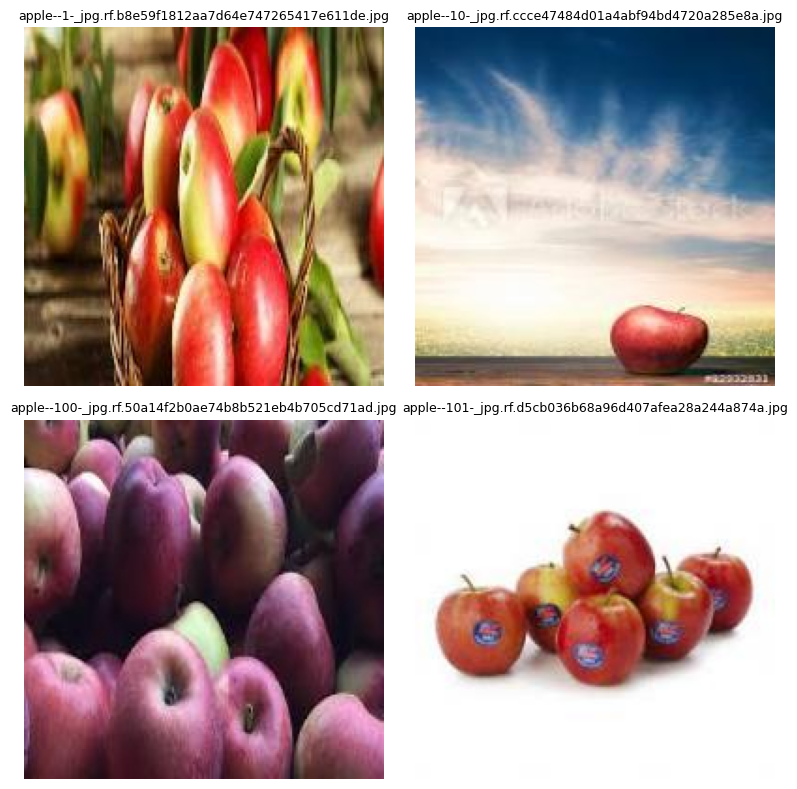

In [29]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for ax, path in zip(axes.flat, df_apple_train['image_file'][:4]):
    ax.imshow(Image.open(path))
    ax.set_title(Path(path).name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


image 1/1 /kaggle/working/../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/train/images/apple--101-_jpg.rf.d5cb036b68a96d407afea28a244a874a.jpg: 640x640 5 apples, 613.3ms
Speed: 41.1ms preprocess, 613.3ms inference, 61.3ms postprocess per image at shape (1, 3, 640, 640)


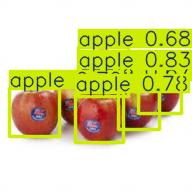

tensor([47., 47., 47., 47., 47.]) tensor([0.8255, 0.7817, 0.7239, 0.6758, 0.6654])


In [30]:
results = model(df_apple_train['image_file'][3])

results[0].show() 
print(results[0].boxes.cls, results[0].boxes.conf)

In [31]:
print(len(df_apple_train))              
print(Image.open(df_apple_train['image_file'][0]).size)  

553
(192, 192)


In [34]:
model.train(data='data.yaml', epochs=50, imgsz=192, batch=32, cache=True, patience=15)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=192, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_m

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7884f8de4050>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [36]:
best = YOLO('runs/detect/train/weights/best.pt')

m = best.val(data='data.yaml', imgsz=192)
print(m.box.map50, m.box.map, m.box.p, m.box.r)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 10.0±6.5 MB/s, size: 5.6 KB)
val: Scanning /kaggle/input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels... 146 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 764.3it/s 0.2s3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.3it/s 4.4s.3s
                   all        146        572      0.421      0.942      0.829      0.524
Speed: 0.1ms preprocess, 13.5ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
0.8289439630852027 0.5243350764411557 [    0.42112]

In [37]:
valid_images, valid_labels = create_paths(valid_data_dir)
df_apple_valid = pd.DataFrame({'image_file': valid_images, 'label_file': valid_labels})
df_apple_valid = df_apple_valid.sort_values('image_file', ignore_index=True)
df_apple_valid.head(5)

,image_file,label_file
0,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--295-_jpg.rf.3e30750b242fc97bfdd68553fd996d91.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels/apple--295-_jpg.rf.3e30750b242fc97bfdd68553fd996d91.txt
1,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--296-_jpg.rf.9c1cbad3e358ffd9640553739d8fc415.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels/apple--296-_jpg.rf.9c1cbad3e358ffd9640553739d8fc415.txt
2,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--297-_jpg.rf.438204baf3c1717b5c2758adefc07905.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels/apple--297-_jpg.rf.438204baf3c1717b5c2758adefc07905.txt
3,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--298-_jpg.rf.04ac1387971444827a604d43e2991694.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels/apple--298-_jpg.rf.04ac1387971444827a604d43e2991694.txt
4,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--299-_jpg.rf.ea03b79125bfdbcfd45514d13b178acf.jpg,../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/labels/apple--299-_jpg.rf.ea03b79125bfdbcfd45514d13b178acf.txt



image 1/1 /kaggle/working/../input/datasets/snehamahata/apple-quality-dataset/Apple_Detection.v1i.yolov8/valid/images/apple--295-_jpg.rf.3e30750b242fc97bfdd68553fd996d91.jpg: 192x192 24 apples, 46.8ms
Speed: 0.7ms preprocess, 46.8ms inference, 1.0ms postprocess per image at shape (1, 3, 192, 192)


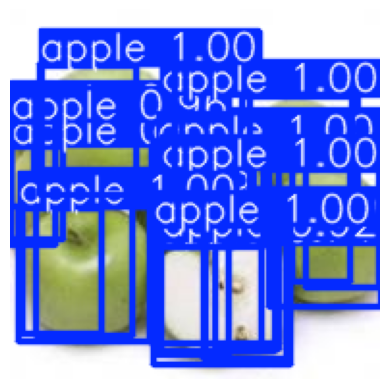

24 apples detected


In [38]:
r = best(df_apple_valid['image_file'][0], imgsz=192, conf=0.25)[0]
plt.imshow(r.plot()[..., ::-1]); plt.axis('off'); plt.show()
print(len(r.boxes), 'apples detected')

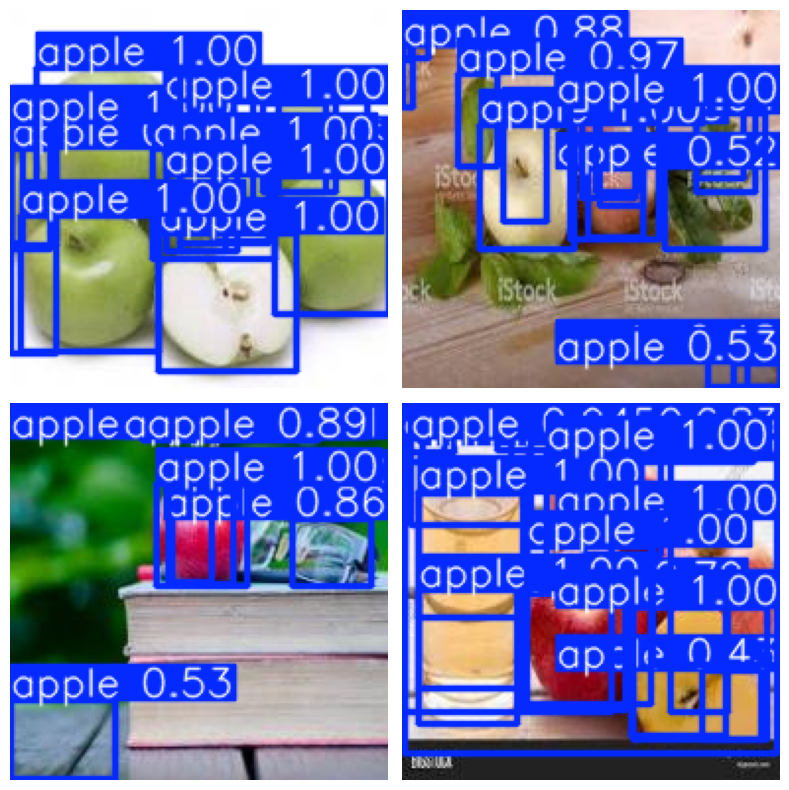

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for ax, p in zip(axes.flat, df_apple_valid['image_file'][:4]):
    ax.imshow(best(p, imgsz=320, verbose=False)[0].plot()[..., ::-1]); ax.axis('off')
plt.tight_layout(); plt.show()
